# Partie 5 — Backtesting hors échantillon

**Principe :** on rejoue l'histoire jour par jour, de 2008 à 2025. Chaque jour $t$, la VaR de chaque méthode est calculée
uniquement avec les 500 jours précédents, puis comparée à la perte réellement observée le jour $t$.

On note $I_t = 1$ si la perte dépasse la VaR (dépassement), $0$ sinon. Une bonne VaR 99 % doit vérifier :
1. **le bon nombre** de dépassements : environ 1 % des jours (test de Kupiec) ;
2. des dépassements **indépendants**, pas groupés pendant les crises (test de Christoffersen) ;
3. peu de dépassements sur chaque année glissante (zones de Bâle).

**Méthodes comparées :** historique, gaussienne, KDE, EVT (Hill, k = 25), GARCH normal, GARCH-t
(paramètres ré-estimés tous les 20 jours).

In [19]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_prices, compute_returns, portfolio_losses
from src.backtest import rolling_var, hits, backtest_table
from src.garch import garch_var_es, var_fhs

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
returns = compute_returns(prices)
losses = portfolio_losses(returns)

methodes = ["hist", "gauss", "kde", "evt", "garch_n", "garch_t"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
chemin = "../data/backtest_var.csv"
if os.path.exists(chemin):
    resultats = pd.read_csv(chemin, index_col=0, parse_dates=True)   
else:
    resultats = rolling_var(losses)                                    
    resultats.to_csv(chemin)

print(resultats.shape)
resultats.head()

(4605, 13)


,perte,hist_95,gauss_95,kde_95,evt_95,garch_n_95,garch_t_95,hist_99,gauss_99,kde_99,evt_99,garch_n_99,garch_t_99
date,,,,,,,,,,,,,
2008-01-02,0.011816,0.01925,0.018261,0.019853,0.019216,0.014150,0.013789,0.030172,0.025812,0.031481,0.031113,0.020121,0.020584
2008-01-03,0.000033,0.01925,0.018305,0.019856,0.019216,0.014985,0.014713,0.030172,0.025864,0.031487,0.031113,0.021301,0.021951
2008-01-04,0.016802,0.01925,0.018276,0.019853,0.019216,0.014353,0.014035,0.030172,0.025830,0.031481,0.031113,0.020407,0.020949
2008-01-07,0.005733,0.01925,0.018296,0.019885,0.019216,0.016385,0.016230,0.030172,0.025856,0.031481,0.031113,0.023281,0.024193
2008-01-08,-0.009945,0.01925,0.018318,0.019884,0.019216,0.015897,0.015720,0.030172,0.025875,0.031479,0.031113,0.022591,0.023439


## 1. Les tests utilisés

**Kupiec**: $x$ dépassements sur $n$ jours, taux promis $p = 1 - \alpha$, taux observé $\hat p = x/n$.
$$H_0 : \text{taux de dépassement} = p \qquad LR_{uc} = -2 \ln \frac{(1-p)^{\,n-x}\,p^{\,x}}{(1-\hat p)^{\,n-x}\,\hat p^{\,x}} \sim \chi^2(1)$$

**Christoffersen (indépendance).** $\pi_0 = P(I_t = 1 \mid I_{t-1} = 0)$, $\pi_1 = P(I_t = 1 \mid I_{t-1} = 1)$.
$$H_0 : \pi_0 = \pi_1 \qquad LR_{ind} = -2 \ln \frac{L(\hat\pi)}{L(\hat\pi_0, \hat\pi_1)} \sim \chi^2(1)$$

Dans les deux cas, on rejette $H_0$ au niveau 5 % si $LR > \chi^2_{0{,}95}(1) = 3{,}84$, c'est-à-dire si la p-value est inférieure à 5 %.

**Zones de Bâle.** Chaque jour, on compte les dépassements de la VaR 99 % sur les 250 jours précédents (2,5 attendus) :
vert (0–4), jaune (5–9), rouge (10 et plus).

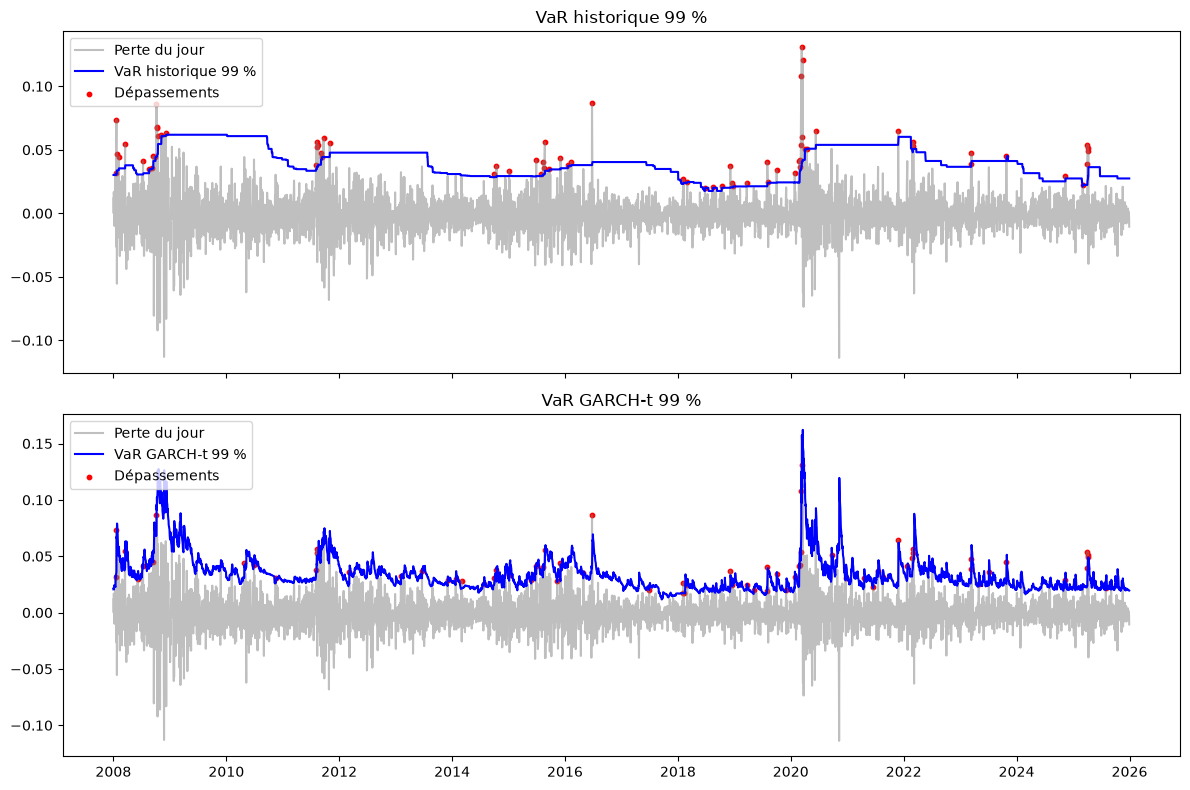

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, m, titre in zip(axes, ["hist", "garch_t"], ["VaR historique 99 %", "VaR GARCH-t 99 %"]):
    var = resultats[m + "_99"]
    dep = resultats[resultats["perte"] > var]
    ax.plot(resultats["perte"], color="gray", alpha=0.5, label="Perte du jour")
    ax.plot(var, color="blue", label=titre)
    ax.scatter(dep.index, dep["perte"], color="red", s=10, label="Dépassements")
    ax.set_title(titre)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../figures/backtest_hist_garch.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation

- **VaR historique :** elle évolue par paliers et réagit en retard. Les dépassements se concentrent au début des crises
  (2008, été 2011, mars 2020), puis la VaR reste élevée pendant deux ans par effet de fenêtre, même après le retour au calme.
- **VaR GARCH-t :** elle suit la volatilité au jour le jour. Elle monte dès le lendemain d'un choc et redescend en période calme :
  ses dépassements sont plus dispersés dans le temps.

In [22]:
tab_99 = backtest_table(resultats, methodes, 0.99)
tab_99

,dépassements,attendus,p Kupiec,pi0 (%),pi1 (%),p Christoffersen,VaR moyenne (%),vert (%),jaune (%),rouge (%),pire année
méthode,,,,,,,,,,,
hist,73,46,0.000,1.479,8.219,0.001,3.960,65.542,25.161,9.298,16.0
gauss,105,46,0.000,2.089,10.476,0.000,3.325,54.982,23.347,21.671,20.0
kde,63,46,0.017,1.255,9.524,0.000,4.128,68.228,25.023,6.749,14.0
evt,68,46,0.002,1.345,10.294,0.000,4.050,68.044,22.062,9.894,17.0
garch_n,91,46,0.000,1.950,3.297,0.403,3.103,49.311,45.087,5.601,13.0
garch_t,74,46,0.000,1.567,4.054,0.155,3.394,56.382,41.460,2.158,12.0


### Résultats à 99 % 

**Kupiec :** aucune méthode ne passe. La gaussienne (105 dépassements) est la plus éloignée, à cause de sa queue fine ;
la KDE (63) est la plus proche (p = 0,017).

**Christoffersen :** les méthodes non conditionnelles (historique, gaussienne, KDE, EVT) sont rejetées. Après un dépassement,
la probabilité d'un nouveau dépassement passe d'environ 1,5 % à 8–10 % : les depassements s'enchaînent, car ces VaR
réagissent trop lentement aux crises( Var na pas le temps de s'ajuster). Les deux GARCH passent le test (p = 0,40 et 0,16) : ils réagissent dès le lendemain d'un choc.

**Zones de Bâle :** la gaussienne passe 22 % du temps en zone rouge. Les méthodes non conditionnelles basculent en rouge
pendant les crises (7 à 10 % du temps). Le GARCH-t n'y passe que 2 % du temps, avec la pire année la moins mauvaise (12),
au prix d'un passage fréquent en zone jaune (41 %).

**Coût en capital :** le GARCH-t a une VaR moyenne plus faible (3,39 %) que l'historique (3,96 %) : il immobilise moins de capital
en période calme et l'augmente en crise.

In [23]:
tab_95 = backtest_table(resultats, methodes, 0.95)
tab_95

,dépassements,attendus,p Kupiec,pi0 (%),pi1 (%),p Christoffersen,VaR moyenne (%)
méthode,,,,,,,
hist,250,230,0.188,4.777,16.800,0.000,2.276
gauss,241,230,0.471,4.630,16.183,0.000,2.342
kde,241,230,0.471,4.630,16.183,0.000,2.338
evt,250,230,0.188,4.777,16.800,0.000,2.273
garch_n,263,230,0.030,5.413,10.646,0.001,2.172
garch_t,290,230,0.000,5.934,11.724,0.000,2.101


### Résultats à 95 % (230 dépassements attendus)

| Méthode |  Verdict |
|---|---|
| Gaussienne | non rejetée |
| KDE | non rejetée |
| Historique |non rejetée |
| EVT | non rejetée |
| GARCH normal |  rejetée |
| GARCH-t | rejetée |

**Les méthodes non conditionnelles passent le test de Kupiec.** La VaR 95 % porte sur des pertes peu extrêmes
(1 jour sur 20) : à ce niveau, la forme de la distribution compte peu, et même la loi normale donne le bon nombre de dépassements.

**Les deux GARCH sont rejetés, pour une raison opposée à celle observée à 99 %.** En période calme, la volatilité prévue
devient très faible : la VaR GARCH descend très bas et la moindre secousse la dépasse. Le GARCH-t est le plus touché :
à 95 %, le quantile de la loi de Student standardisée (≈ 1,59) est plus faible que celui de la loi normale (1,64),
car la Student concentre plus de masse au centre et dans les queues extrêmes, et moins dans les « épaules » de la distribution.


**En revanche, toutes les méthodes sont rejetées par Christoffersen à 95 %** : après un dépassement, la probabilité
d'un nouveau dépassement passe d'environ 5 % à 11–17 %. Le nombre de dépassements est correct pour les méthodes
non conditionnelles, mais ils restent groupés dans le temps.



**Conclusion :** le classement des méthodes dépend du niveau de confiance. À 95 %, les méthodes simples suffisent ;
à 99 %, niveau réglementaire, ce sont la queue de distribution et la réactivité aux crises qui font la différence.

In [24]:
periodes = {
    "Crise 2008-2009": ("2008-01-01", "2009-12-31"),
    "Dette euro 2011": ("2011-01-01", "2011-12-31"),
    "Calme 2013-2019": ("2013-01-01", "2019-12-31"),
    "Covid 2020": ("2020-02-01", "2020-06-30"),
    "Année 2022": ("2022-01-01", "2022-12-31"),
}

tab_periodes = pd.DataFrame({
    nom: {m: 100 * hits(resultats.loc[d:f, "perte"], resultats.loc[d:f, m + "_99"]).mean() for m in methodes}
    for nom, (d, f) in periodes.items()
}).round(2)

print("Taux de dépassement de la VaR 99 % par période (en %, attendu : 1 %)")
tab_periodes

Taux de dépassement de la VaR 99 % par période (en %, attendu : 1 %)


,Crise 2008-2009,Dette euro 2011,Calme 2013-2019,Covid 2020,Année 2022
hist,3.12,3.11,1.40,10.58,0.78
gauss,4.30,3.89,2.29,14.42,1.56
kde,2.54,3.11,1.17,9.62,0.78
evt,3.32,3.11,1.23,9.62,0.78
garch_n,1.95,1.95,1.90,7.69,1.95
garch_t,1.37,1.56,1.73,4.81,1.56


### Résultats par sous-période (VaR 99 %, taux de dépassement attendu : 1 %)

**En crise, le GARCH-t est nettement le meilleur.**
- Crise 2008-2009 : 1,37 % pour le GARCH-t, contre 2,5 à 4,3 % pour les méthodes non conditionnelles.
- Dette euro 2011 : 1,56 % contre 3,1 à 3,9 %.
- Covid 2020 : toutes les méthodes échouent, car le choc est brutal et sans précédent. Mais le GARCH-t
  (4,81 %) se trompe deux à trois fois moins que l'historique (10,58 %) ou la gaussienne (14,42 %).

Les méthodes non conditionnelles utilisent une fenêtre de 500 jours souvent calmes au début des crises :
leur VaR est trop basse au moment où les pertes extrêmes arrivent.

**En période calme, les méthodes non conditionnelles sont meilleures.**
- Calme 2013-2019 : KDE 1,17 %, EVT 1,23 %, historique 1,40 %, très proches de 1 %.
  Les GARCH (1,7 à 1,9 %) font trop de dépassements : leur volatilité prévue devient très faible quand le marché
  est calme, et la moindre secousse dépasse la VaR.

**En 2022, l'effet fantôme est visible.** Les méthodes non conditionnelles n'ont que 0,78 % de dépassements :
leur fenêtre de 500 jours contient encore le Covid, ce qui maintient leur VaR à un niveau élevé alors que le
risque a baissé. Elles sont trop prudentes, donc trop coûteuses en capital.

**La gaussienne est la pire sur toutes les périodes.** Même en période calme (2,29 %), sa queue fine
sous-estime les pertes extrêmes.

## Conclusion du backtest

**Aucune méthode ne passe l'ensemble des tests à 99 % sur 2008–2025**, mais elles échouent pour des raisons différentes :

| | Non conditionnelles (historique, KDE, EVT) | GARCH-t |
|---|---|---|
| Réaction aux crises | lente (fenêtre de 500 jours) | rapide (dès le lendemain) |
| Dépassements (Kupiec) | trop nombreux (63 à 73) | trop nombreux (74) |
| Indépendance (Christoffersen) | rejetée : violations groupées | non rejetée |
| Zone rouge de Bâle | 7 à 10 % du temps | 2 % du temps |
| En crise | mauvaises | les meilleures |
| En période calme | les meilleures | un peu trop optimistes |
| Capital moyen | 3,96 % (historique) | 3,39 % |

**Le GARCH-t est la méthode la plus robuste** : il se trompe un peu trop souvent, mais jamais
en série, presque jamais en zone rouge, et il immobilise moins de capital en moyenne (l’historique garde une VaR haute pendant 2 ans après chaque crise (effet fantôme), même quand le marché est redevenu calme. Il bloque de l’argent pour rien.
Le GARCH-t baisse sa VaR dès que le marché se calme, et la monte quand ça s’agite. Il bloque de l’argent seulement quand c’est nécessaire )

**Une prévision fiable doit combiner deux propriétés :** une queue épaisse et une réactivité aux changements
de volatilité. La simulation historique filtrée (FHS), qui associe la volatilité GARCH aux chocs historiques réels,
est la suite naturelle de ce travail.

## 6. Amélioration : la simulation historique filtrée (FHS)

Le GARCH-t est la méthode la plus robuste, mais il compte encore trop de dépassements à 99 % (74 contre 46 attendus).
Sa VaR s'écrit :
$$\text{VaR}^{\text{GARCH-t}} = \mu + \sigma_{t+1} \times z_{\text{Student}}$$
La volatilité prévue $\sigma_{t+1}$ fait sa force (réactivité). En revanche, le quantile $z$ vient d'une loi de Student
symétrique, alors que les pertes ont une queue plus épaisse que les gains (skewness négative, partie 1).

**Idée de la FHS** : garder $\sigma_{t+1}$, mais remplacer le quantile théorique par le quantile empirique des chocs
standardisés $z_t = (r_t - \mu)/\sigma_t$ de la fenêtre :
$$\text{VaR}^{FHS} = \mu + \sigma_{t+1} \times q_{\alpha}\big(z_{t-499}, \dots, z_t\big)$$
On combine ainsi la **réactivité** du GARCH et la **forme réelle** de la queue, sans hypothèse de loi.

In [25]:
from src.backtest import rolling_fhs

chemin_fhs = "../data/backtest_fhs.csv"
if os.path.exists(chemin_fhs):
    fhs = pd.read_csv(chemin_fhs, index_col=0, parse_dates=True)
else:
    fhs = rolling_fhs(losses)            
    fhs.to_csv(chemin_fhs)

resultats_fhs = resultats.join(fhs)
backtest_table(resultats_fhs, ["garch_t", "fhs"], 0.99)

,dépassements,attendus,p Kupiec,pi0 (%),pi1 (%),p Christoffersen,VaR moyenne (%),vert (%),jaune (%),rouge (%),pire année
méthode,,,,,,,,,,,
garch_t,74,46,0.000,1.567,4.054,0.155,3.394,56.382,41.460,2.158,12.0
fhs,60,46,0.048,1.298,1.667,0.811,3.697,78.283,21.694,0.023,10.0


In [26]:
backtest_table(resultats_fhs, ["garch_t", "fhs"], 0.95)

,dépassements,attendus,p Kupiec,pi0 (%),pi1 (%),p Christoffersen,VaR moyenne (%)
méthode,,,,,,,
garch_t,290,230,0.0,5.934,11.724,0.0,2.101
fhs,255,230,0.1,5.151,12.157,0.0,2.260


In [28]:
tab_periodes_fhs = pd.DataFrame({
    nom: {m: 100 * hits(resultats_fhs.loc[d:f, "perte"], resultats_fhs.loc[d:f, m + "_99"]).mean()
    for m in ["hist", "garch_t", "fhs"]}
    for nom, (d, f) in periodes.items()
}).round(2)

print("Taux de dépassement de la VaR 99 % par période (en %, attendu : 1 %)")
tab_periodes_fhs

Taux de dépassement de la VaR 99 % par période (en %, attendu : 1 %)


,Crise 2008-2009,Dette euro 2011,Calme 2013-2019,Covid 2020,Année 2022
hist,3.12,3.11,1.40,10.58,0.78
garch_t,1.37,1.56,1.73,4.81,1.56
fhs,0.98,1.17,1.73,2.88,1.17


### Résultats de la FHS

**À 99 %, la FHS est la meilleure méthode testée.**

| | GARCH-t | FHS |
|---|---|---|
| Dépassements (46 attendus) | 74 | **60** |
| p Kupiec | 0,0001 | **0,048** |
| $\hat\pi_0$ / $\hat\pi_1$ | 1,57 % / 4,05 % | **1,30 % / 1,67 %** |
| p Christoffersen | 0,155 | **0,811** |
| Zone rouge de Bâle | 2,2 % du temps | **0,02 % du temps** |
| VaR moyenne | 3,39 % | 3,70 % |

- Remplacer le quantile de la Student par le quantile empirique des chocs standardisés réduit les dépassements de 74 à 60 :
  la loi de Student symétrique sous-estimait la queue des pertes. La FHS n'est rejetée par Kupiec que de justesse
  (60 dépassements, pour une zone d'acceptation de 34 à 59).
- Ses dépassements sont indépendants : après une violation, la probabilité d'une nouvelle violation reste quasiment
  inchangée (1,3 % contre 1,7 %).
- Elle ne passe pratiquement jamais en zone rouge (0,02 % du temps, pire année : 10 dépassements).
- Ce gain a un coût modéré : une VaR moyenne de 3,70 %, entre le GARCH-t (3,39 %) et l'historique (3,96 %).

**Par période**, la FHS est la plus fiable en crise : 0,98 % de dépassements en 2008-2009 (pour 1 % attendu),
1,17 % en 2011, et 2,88 % pendant le Covid, contre 4,81 % pour le GARCH-t et 10,58 % pour l'historique.
En période calme (2013-2019), elle reste à 1,73 %, comme le GARCH-t : ce défaut vient de la volatilité prévue,
trop faible quand le marché est calme, que la FHS ne modifie pas.

**À 95 %**, la FHS passe le test de Kupiec (p = 0,10), mais ses dépassements restent groupés, comme ceux du GARCH-t.

## Conclusion finale

Sur 2008–2025, aucune méthode ne passe parfaitement tous les tests à 99 %, mais elles échouent pour des raisons différentes :

- **La gaussienne** cumule les défauts : queue trop fine et réaction lente (105 dépassements, 22 % du temps en zone rouge).
- **L'historique, la KDE et l'EVT** ont des queues réalistes mais réagissent trop lentement : leurs dépassements
  s'enchaînent au début des crises, et elles restent trop prudentes après (effet de fenêtre).
- **Le GARCH-t** réagit aux crises (dépassements indépendants), mais sa loi de Student symétrique sous-estime la queue des pertes.
- **La FHS**, qui combine la volatilité du GARCH et la distribution empirique des chocs, est la plus fiable :
  60 dépassements, indépendants, presque jamais en zone rouge, et la meilleure en période de crise.

**Réponse à la problématique :** une prévision de risque fiable, en période calme comme en crise, doit combiner
une volatilité conditionnelle (pour réagir aux changements de régime) et une queue de distribution réaliste
(pour estimer la taille des pertes extrêmes). La FHS réunit ces deux propriétés.

la FHS reste perfectible. En période très calme, la volatilité prévue par le GARCH
devient trop faible, et toutes les méthodes conditionnelles(le GARCH normal, le GARCH-t et la FHS) sous-estiment légèrement le risque. D'autres approches pourraient
faire mieux et mériteraient d'être backtestées de la même façon : un GARCH asymétrique (GJR-GARCH), qui réagit plus fortement
aux baisses qu'aux hausses, ou une combinaison GARCH-EVT, qui modélise la queue des chocs standardisés par la théorie des valeurs extrêmes.